# The Eye searches for the Ring
*Solving an optimization problem, step by step.*

Sauron is looking for the One Ring. Four of his Nazgûl are out riding, and each
of them can sense the Ring. The sense is limited: a Nazgûl feels how far away
the Ring is, but not in which direction, and the feeling is a little off. Each
Nazgûl reports back one number, its distance to the Ring.

Where is the Ring?

In [96]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from itertools import count, islice

Point = np.ndarray  # (x, y) on the map, in leagues
NOISE = 0.3  # how far off a reading typically is, in leagues

ring = np.array([0.0, 0.0])  # only used to make up the readings
nazguls = np.array([[12.0, -3.0], [13.0, -1.0], [12.5, 1.0], [13.5, 3.0]])

rng = np.random.default_rng(1)
distances = np.linalg.norm(nazguls - ring, axis=1)
readings = distances + NOISE * rng.standard_normal(len(nazguls))
readings

array([12.47299213, 13.28489025, 12.63906733, 13.43836952])

A reading says that the Ring lies somewhere on a circle around that Nazgûl.
With exact readings all four circles would pass through the Ring. The readings
are a little off, so the circles only nearly meet.

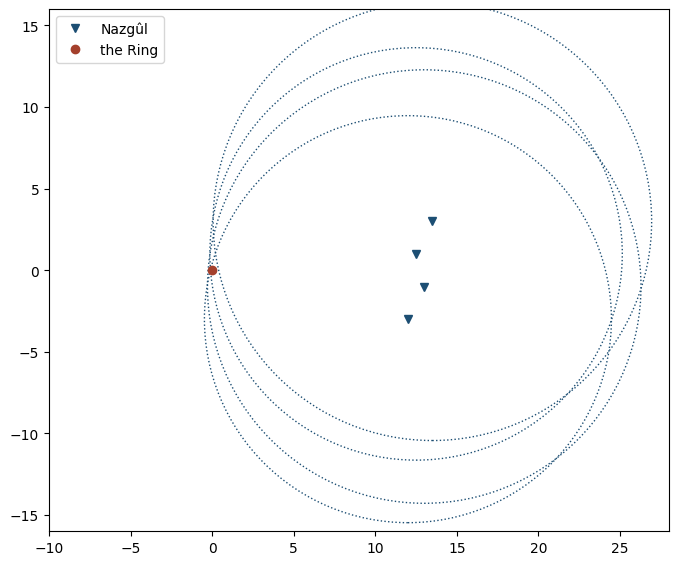

In [97]:
MADDER, PRUSSIAN, VERDIGRIS = '#a4402c', '#1c4e73', '#2b6f68'
OCHRE, CONSTRUCT = '#b58a1e', '#c3c9cf'

def draw_scene():
    plt.figure(figsize=(8, 7))
    for n, d in zip(nazguls, readings):
        circle = plt.Circle(n, d, fill=False, ls=':', color=PRUSSIAN)
        plt.gca().add_patch(circle)
    plt.plot(*nazguls.T, 'v', color=PRUSSIAN, label='Nazgûl')
    plt.plot(*ring, 'o', color=MADDER, label='the Ring')
    plt.axis((-10, 28, -16, 16))
    plt.gca().set_aspect('equal')

draw_scene()
plt.legend();

## I. One dimension

Start with an easier version. Suppose the Ring is known to lie on the East Road,
and that the road is completely straight. A guess is then a single number $s$:
how many leagues along the road from where it starts.

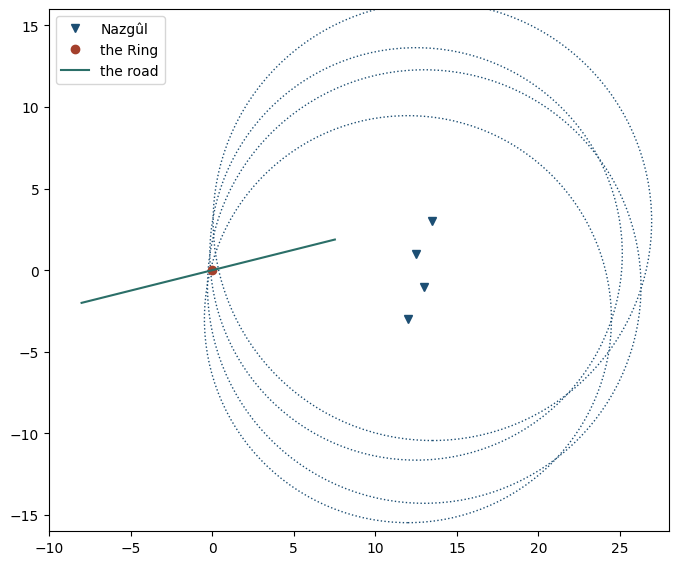

In [98]:
road_start = np.array([-8.0, -2.0])
road_direction = np.array([4.0, 1.0]) / np.sqrt(17)  # unit length

def road(s: float) -> Point:
    return road_start + s * road_direction

draw_scene()
plt.plot(*zip(road(0), road(16)), color=VERDIGRIS, label='the road')
plt.legend();

**How wrong is a guess?** Take a guess $p$ and measure its distance to each
Nazgûl. Had the guess been right, those distances would match the readings. The
difference for Nazgûl $i$ is called its *residual*:

$$r_i(p) = \lVert p - n_i \rVert - d_i$$

where $n_i$ is where the Nazgûl stands and $d_i$ is its reading. In the figure,
the residuals are the red gaps between a guess on the road and the circles.

array([3.76638855, 3.83456578, 4.10386476, 4.63603407])

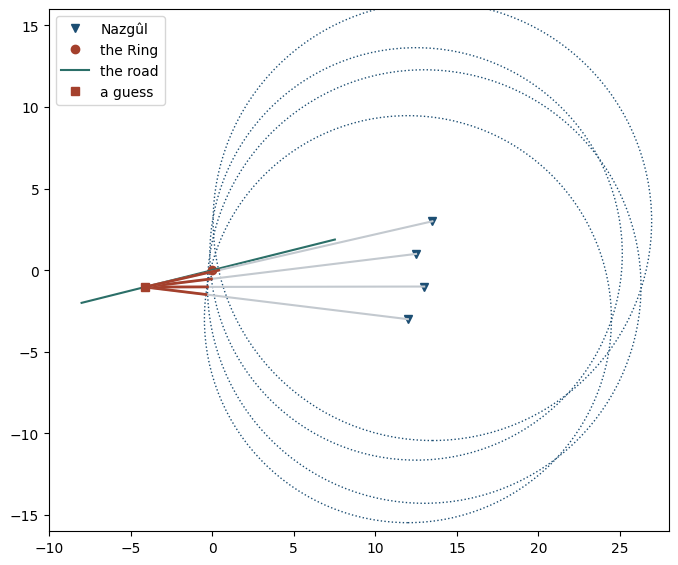

In [99]:
def residuals(p: Point) -> np.ndarray:
    return np.linalg.norm(p - nazguls, axis=1) - readings

def draw_residuals(p: Point):
    for n, d in zip(nazguls, readings):
        edge = n + d * (p - n) / np.linalg.norm(p - n)
        plt.plot(*zip(n, p), color=CONSTRUCT)
        plt.plot(*zip(edge, p), color=MADDER, lw=2)
    plt.plot(*p, 's', color=MADDER, label='a guess')

guess = road(4.0)
draw_scene()
plt.plot(*zip(road(0), road(16)), color=VERDIGRIS, label='the road')
draw_residuals(guess)
plt.legend()
residuals(guess)

**The cost.** Square the residuals, so that too far and too near both count, and
add them up. The result is one number, small for a good guess and large for a
bad one:

$$f(p) = \tfrac12 \sum_i r_i(p)^2$$

Every optimization problem has this shape: an input that may be varied, and one
number to make as small as possible. On the road the input is $s$, and the cost
is $\phi(s) = f(\mathrm{road}(s))$.

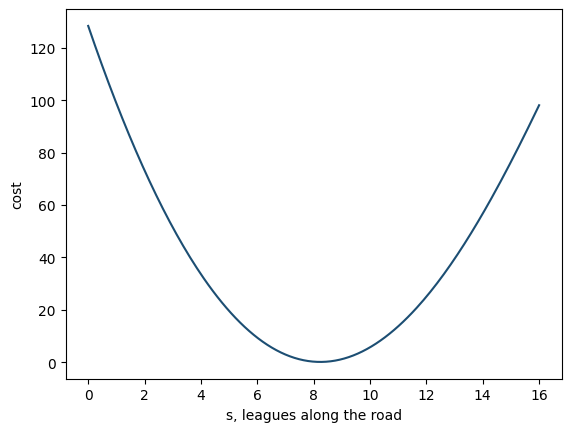

In [100]:
def f(p: Point) -> float:
    return 0.5 * (residuals(p)**2).sum()

def phi(s: float) -> float:
    return f(road(s))

along = np.linspace(0, 16, 200)
plt.plot(along, [phi(s) for s in along], color=PRUSSIAN)
plt.xlabel('s, leagues along the road'); plt.ylabel('cost');

**Bracketing.** Three points $a < b < c$ with $\phi(b)$ below both ends trap
a minimum in $(a, c)$. Two comparisons, no arithmetic.

In [101]:
a, b, c = 0.0, 8.0, 16.0
print(phi(a), phi(b), phi(c))

128.38383615885124 0.21986065336545324 98.10459166774402


**Halving the bracket.** Probe just either side of the middle. The minimum lies
on the side of the smaller value, so the other half can go. Two evaluations buy
half the width.

In [102]:
EPS = 1e-3

def halve(f, a: float, c: float, steps: int) -> float:
    for _ in range(steps):
        m = (a + c) / 2
        if f(m - EPS) < f(m + EPS):
            c = m + EPS
        else:
            a = m - EPS
    return (a + c) / 2

halve(phi, a, c, 10)  # 20 evaluations shrink the bracket a thousandfold

8.242157226562497

**Where the slope is zero.** At the lowest point $\frac{d\phi}{ds} = 0$. Write
$\rho_i(s) = \lVert \mathrm{road}(s) - n_i \rVert$ for the distance a Nazgûl would
see, and $u$ for the road's direction. The chain rule through the square root gives

$$\frac{d\rho_i}{ds} = \frac{(\mathrm{road}(s) - n_i) \cdot u}{\rho_i}, \qquad
\frac{d\phi}{ds} = \sum_i (\rho_i - d_i)\,\frac{d\rho_i}{ds}$$

Differentiating once more,
$\frac{d^2\rho_i}{ds^2} = \bigl(1 - (\frac{d\rho_i}{ds})^2\bigr)/\rho_i$, so

$$\frac{d^2\phi}{ds^2} = \sum_i \Bigl(\frac{d\rho_i}{ds}\Bigr)^2
+ (\rho_i - d_i)\,\frac{d^2\rho_i}{ds^2}$$

In [103]:
def along_road(s: float) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    "Distance from road(s) to each Nazgûl, and its first two derivatives in s."
    d = road(s) - nazguls
    rho = np.linalg.norm(d, axis=1)
    drho = d @ road_direction / rho
    return rho, drho, (1 - drho**2) / rho

def dphi(s: float) -> float:
    rho, drho, _ = along_road(s)
    return ((rho - readings) * drho).sum()

def d2phi(s: float) -> float:
    rho, drho, d2rho = along_road(s)
    return (drho**2 + (rho - readings) * d2rho).sum()

print(dphi(a), dphi(c))  # downhill to the right at a, to the left at c

-31.487905746590997 22.35126403506933


**Newton's method for equations.** Where does the road cross the circle of the
first Nazgûl? That is the equation $g(s) = \rho_0(s) - d_0 = 0$. Replace $g$ by
its tangent line, solve that, and repeat from there. With $g'$ for the slope
$\frac{dg}{ds}$:

$$s_{n+1} = s_n - \frac{g(s_n)}{g'(s_n)}$$

Every method from here on produces a sequence of guesses, so each is written as
a generator that yields where it stands, and `take` collects the first few.

In [104]:
def take(guesses, n: int) -> np.ndarray:
    return np.array(list(islice(guesses, n)))

def newton_1d(g, dg, x: float):
    while True:
        yield x
        x = x - g(x) / dg(x)

def crossing(s: float) -> float:
    return along_road(s)[0][0] - readings[0]

def crossing_slope(s: float) -> float:
    return along_road(s)[1][0]

take(newton_1d(crossing, crossing_slope, 0.0), 6)

array([0.        , 7.89279989, 8.12832157, 8.1288512 , 8.1288512 ,
       8.1288512 ])

**Newton's method for a minimum.** The lowest point solves $\frac{d\phi}{ds} = 0$,
so use the same method with $g = \frac{d\phi}{ds}$. The slope of the slope is the
second derivative. The correct digits double each step.

$$s_{n+1} = s_n - \frac{\phi'(s_n)}{\phi''(s_n)}$$

In [105]:
best_on_road = take(newton_1d(dphi, d2phi, 2.0), 6)
best_on_road

array([2.        , 8.09084548, 8.23714096, 8.23735925, 8.23735925,
       8.23735925])

## II. Least squares

Now drop the road: the Ring may be anywhere on the map, and a guess is a point
$p$ with two coordinates. One trick turns the problem into a linear one. Squaring
a reading gives a circle equation,
$\lVert p \rVert^2 - 2\,n_i^{\mathsf T} p + \lVert n_i \rVert^2 = d_i^2$.
The $\lVert p \rVert^2$ term is the same in every one, so subtracting the first
equation from the others leaves equations that are *linear* in $p$:

$$2\,(n_0 - n_i)^{\mathsf T} p = d_i^2 - d_0^2 - \lVert n_i \rVert^2 + \lVert n_0 \rVert^2$$

Three equations, two unknowns, and noisy right-hand sides: linear least squares,
solved by the normal equations $A^{\mathsf T} A\,p = A^{\mathsf T} y$.

[-0.73846259  0.81345589] 1.1515064499768468
[-1.77635684e-15 -7.10542736e-15] the residual is orthogonal to every column of A


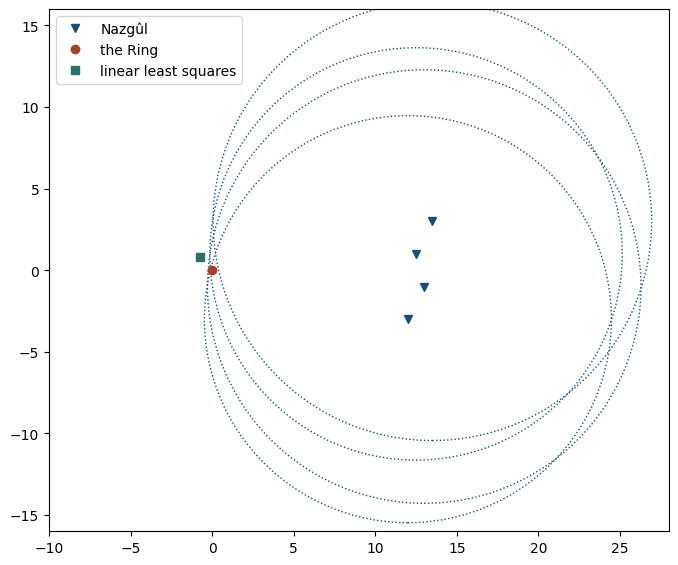

In [106]:
A = 2 * (nazguls[0] - nazguls[1:])
y = (readings[1:]**2 - readings[0]**2
     - (nazguls[1:]**2).sum(axis=1) + nazguls[0] @ nazguls[0])

linear = np.linalg.solve(A.T @ A, A.T @ y)
print(linear, f(linear))
print(A.T @ (y - A @ linear), 'the residual is orthogonal to every column of A')

draw_scene()
plt.plot(*linear, 's', color=VERDIGRIS, label='linear least squares')
plt.legend();

**Gauss–Newton.** The linear trick minimizes a cousin of $f$, not $f$ itself. To
minimize $f$, linearize the residuals instead. The gradient of each residual is the
unit vector $u_i$ pointing from Nazgûl $i$ to $p$, written as a row. Stacked, these
rows are the Jacobian $J$ of $r$:

$$\nabla r_i = \frac{(p - n_i)^{\mathsf T}}{\lVert p - n_i \rVert} = u_i^{\mathsf T}$$

With $r(p_n + h) \approx r_n + J_n h$, each step is a linear least-squares problem,
solved by the normal equations. The step has the shape of Newton's
$s_{n+1} = s_n - \phi'(s_n)/\phi''(s_n)$, with the gradient $J^{\mathsf T} r$ for
the slope and $J^{\mathsf T} J$ for the bend, $J$ evaluated at $p_n$:

$$p_{n+1} = p_n - \bigl(J^{\mathsf T} J\bigr)^{-1} J^{\mathsf T}\, r(p_n)$$

In [107]:
def jacobian(p: Point) -> np.ndarray:
    d = p - nazguls
    return d / np.linalg.norm(d, axis=1)[:, None]

def gauss_newton(residuals, jacobian, p: Point):
    while True:
        yield p
        r, J = residuals(p), jacobian(p)
        p = p - np.linalg.solve(J.T @ J, J.T @ r)

def values(path: np.ndarray) -> np.ndarray:
    return np.array([f(p) for p in path]).round(3)

START = np.array([2.0, 4.0])  # a poor start, used again below
print(jacobian(START))

# compare to linear least squares
from_linear = take(gauss_newton(residuals, jacobian, linear), 5)
minimum = from_linear[-1]  # save minimum for the plot later
print(values(from_linear))

print(values(take(gauss_newton(residuals, jacobian, START), 5)))

[[-0.81923192  0.57346234]
 [-0.91036648  0.41380294]
 [-0.96152395  0.27472113]
 [-0.99624059  0.08662962]]
[4.03  0.34  0.054 0.054 0.054]


## III. Several variables

Gauss–Newton relies on the cost being a sum of squares. The methods from here on
need only the cost and its derivatives, and walk downhill on it. Drawn over the
whole map, the cost is a landscape, and they look for its lowest point.

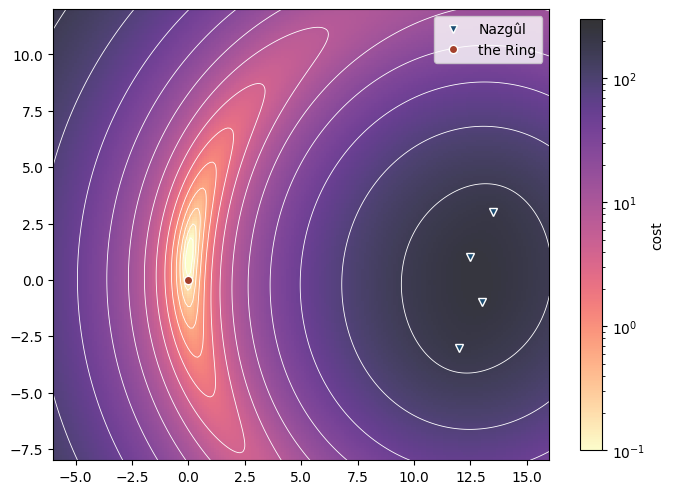

In [108]:
MAP = (-6, 16, -8, 12)
CLOSE = (-3, 5, -2, 7)  # the valley the Ring lies in
LEVELS = np.geomspace(0.1, 300, 14)  # costs drawn, on a log scale

def draw_map(extent=MAP):
    x, y = np.meshgrid(np.linspace(*extent[:2], 200),
                       np.linspace(*extent[2:], 200))
    z = np.vectorize(lambda x, y: f(np.array([x, y])))(x, y)
    plt.figure(figsize=(8, 7))
    norm = LogNorm(LEVELS[0], LEVELS[-1])
    cells = plt.pcolormesh(x, y, z, norm=norm, cmap='magma_r', alpha=0.8)
    plt.colorbar(cells, label='cost', shrink=0.8)
    plt.contour(x, y, z, levels=LEVELS, colors='white', linewidths=0.6)
    plt.plot(*nazguls.T, 'v', color=PRUSSIAN, mec='white', label='Nazgûl')
    plt.plot(*ring, 'o', color=MADDER, mec='white', label='the Ring')
    plt.axis(extent)
    plt.gca().set_aspect('equal')

def draw_path(path: np.ndarray, color: str, label: str):
    plt.plot(*path.T, '.-', color=color, lw=1.2, ms=5, label=label)

draw_map()
plt.legend();

The methods need the gradient. With the Jacobian from Gauss–Newton, the chain rule
gives it in one line: $\nabla f = r^{\mathsf T} J$.

In [109]:
def grad(p: Point) -> np.ndarray:
    return residuals(p) @ jacobian(p)

**Gradient descent.** Step against the gradient, a fixed step length at a time:
$p_{n+1} = p_n - \alpha\,\nabla f(p_n)^{\mathsf T}$.

In [110]:
ALPHA = 0.4

def gradient_descent(grad, p: Point, alpha: float):
    while True:
        yield p
        p = p - alpha * grad(p)

path = take(gradient_descent(grad, START, ALPHA), 40)
print(path[-1], values(path)[::5])

[0.08273435 1.54250139] [4.03  0.514 0.331 0.224 0.158 0.118 0.093 0.078]


**Choosing a step length.** Too long a step, and the cost climbs instead.

In [111]:
values(take(gradient_descent(grad, START, 0.6), 8))

array([  4.03 ,   6.373,  10.693,  17.96 ,  31.472,  52.1  ,  91.434,
       132.617])

**The zig-zag.** With every Nazgûl to the east, the readings pin down how far east
the Ring is and hardly at all how far north. The bowl is long and thin, and the
gradient points across the valley. The Hessian measures that: differentiating the
gradient once more gives

$$H = \sum_i u_i u_i^{\mathsf T} + \frac{r_i}{\rho_i}\,(I - u_i u_i^{\mathsf T})$$

where $\rho_i = \lVert p - n_i \rVert$ is the distance from the guess to Nazgûl $i$.
The first sum is $J^{\mathsf T} J$, the part Gauss–Newton keeps. The ratio of the
Hessian's eigenvalues says how much error each step leaves behind.

In [112]:
def hessian(p: Point) -> np.ndarray:
    rho = np.linalg.norm(p - nazguls, axis=1)
    bends = (np.outer(u, u) + r / d * (np.eye(2) - np.outer(u, u))
             for u, r, d in zip(jacobian(p), residuals(p), rho))
    return sum(bends)

lo, hi = np.linalg.eigvalsh(hessian(minimum))
kappa = hi / lo
print(f'condition number {kappa:.1f}')
print(f'error left per step {(kappa - 1) / (kappa + 1):.3f}')

condition number 32.6
error left per step 0.941


**Adam** gives each coordinate its own step length: the step is divided by the
size of that coordinate's recent gradients, so the steep direction across the
valley no longer sets the pace for the shallow one along it.

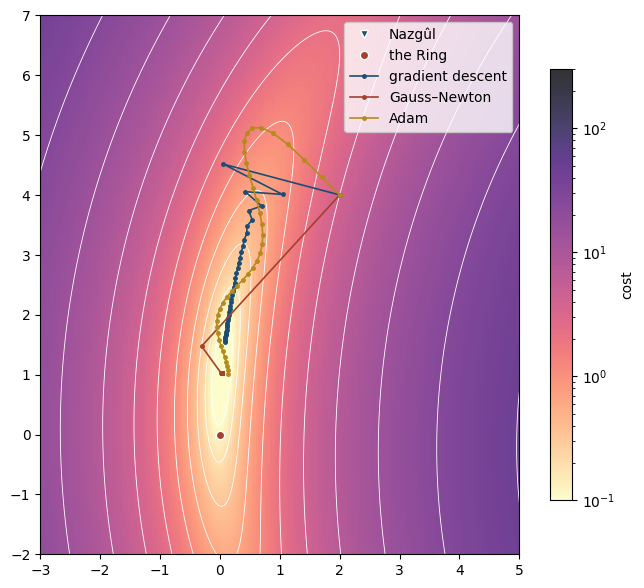

In [113]:
def adam(grad, p: Point, alpha: float, b1=0.9, b2=0.999):
    m = s = 0
    for k in count(1):
        yield p
        g = grad(p)
        m = b1 * m + (1 - b1) * g
        s = b2 * s + (1 - b2) * g**2
        p = p - alpha * m / (1 - b1**k) / (np.sqrt(s / (1 - b2**k)) + 1e-8)

draw_map(extent=CLOSE)
draw_path(take(gradient_descent(grad, START, ALPHA), 40), PRUSSIAN, 'gradient descent')
draw_path(take(gauss_newton(residuals, jacobian, START), 40), MADDER, 'Gauss–Newton')
draw_path(take(adam(grad, START, 0.3), 40), OCHRE, 'Adam')
plt.legend();